# Decoding

In [1]:
import pandas as pd
import numpy as np
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from matplotlib.lines import Line2D
from sklearn.metrics import accuracy_score, f1_score
import sys
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT.parent / 'LB'))
from src.decoding import cleandfdecodingTS

path = '/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/ieeg_shortWOBS_fs250/BJH026_info.json'
with open(path) as json_data:
    d = json.load(json_data)
    time = d['time_epoch']

In [2]:
band = 'broadband'
method_pca = 'mean'
data_aug_method = 'mean'
PC_use = 0
model_name = 'LR'
dim_red_method = 'PLSSVD'

KeysView(NpzFile 'out/plssvd_eval_equal_var/paired_coverage/none/iteration_000/scores_000.npz' with keys: train_ieeg, train_meg, test_ieeg, test_meg, ieeg_prediction_bb...)


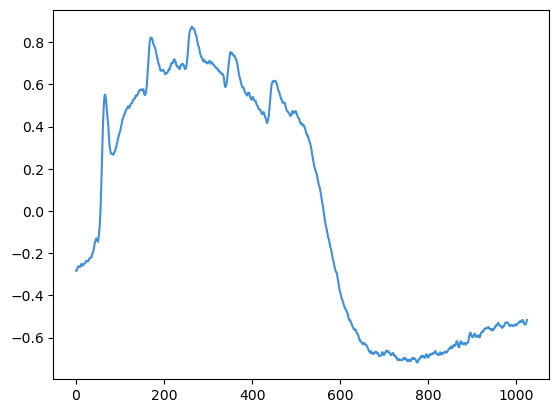

In [3]:
file='out/plssvd_eval_equal_var/paired_coverage/none/iteration_000/scores_000.npz'
with np.load(file,allow_pickle=False) as saved:
    print(saved.keys())
    plt.plot(saved['train_ieeg'][:, 0].T)

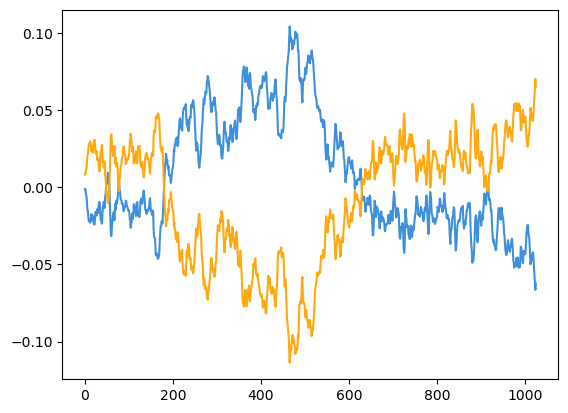

In [5]:
file = f'out/decoding/ieeg/broadband/fullmodel/{dim_red_method}_{method_pca}_{data_aug_method}_{PC_use}_{model_name}full_iteration0_time_courses.npz'
with np.load(file,allow_pickle=False) as saved:
    plt.plot(saved['train_time_courses'].mean(1).T)

In [54]:
file

'out/decoding/ieeg/broadband/fullmodel/PLSSVD_mean_mean_0_LRfull_iteration0_time_courses.npz'

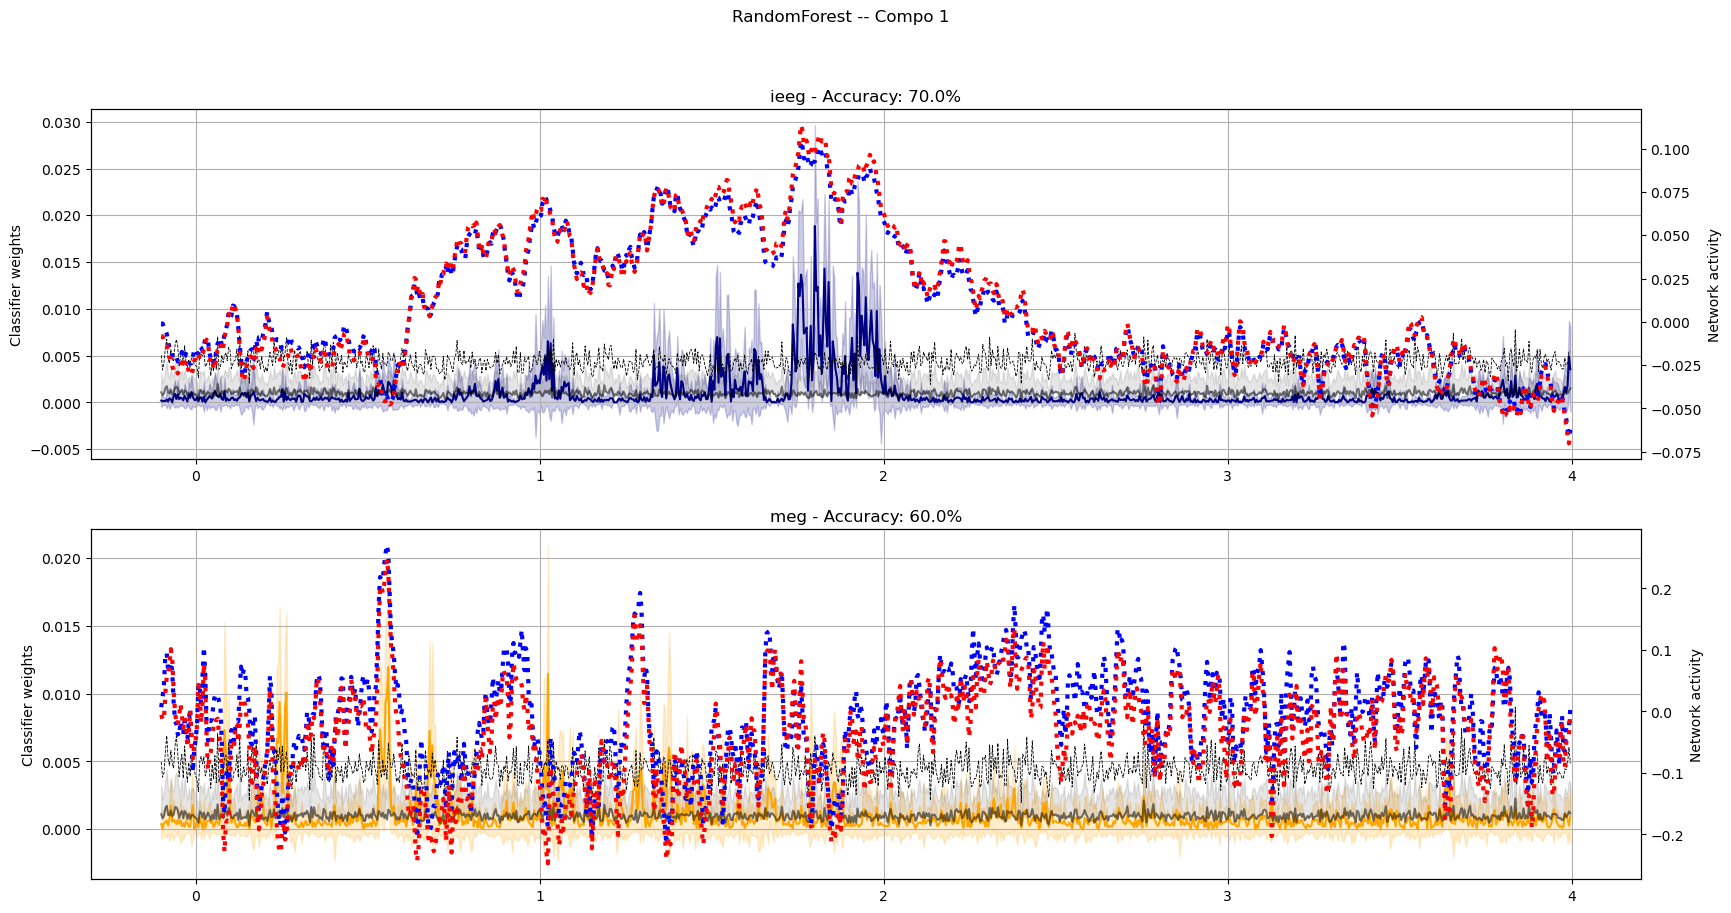

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(20, 10))

color ={'ieeg' : 'navy', 'meg' : 'orange'}
fig.suptitle(f'{model_name} -- Compo {PC_use+1}')

for d, dataset_ in enumerate(['ieeg', 'meg']):

    file = f'out/decoding/{dataset_}/broadband/fullmodel/{dim_red_method}_{method_pca}_{data_aug_method}_{PC_use}_{model_name}full_iteration0_time_courses.npz'
    with np.load(file,allow_pickle=False) as saved:
        train = saved['train_condition_mean']
   
    df_final = pd.read_csv(f'out/decoding/{dataset_}/{band}/fullmodel/{method_pca}_{data_aug_method}_{PC_use}_{model_name}full.csv')
    result = cleandfdecodingTS(df_final, len(time))
    weight_mean= np.abs(result['weight']).mean(0)
    weight_std= np.abs(result['weight']).std(0)
    weight_sh_mean= result['weight_sh_mean']
    weight_sh_std= result['weight_sh_std']

    ax[d].plot(time, weight_mean, color=color[dataset_])
    ax[d].fill_between(time, weight_mean - weight_std,weight_mean+weight_std, alpha = 0.2, color = color[dataset_])
    
    ax[d].plot(time, weight_sh_mean, color='black',alpha=0.5,  label = f'Mean {int(df_final.loc[0, "iter_perm"])}-perm model over {int(df_final.loc[0, "iter"])} iter')
    ax[d].fill_between(time, abs(weight_sh_mean), abs(weight_sh_mean) + weight_sh_std, alpha = 0.1, color = 'black', label = f'Sd {int(df_final.loc[0, "iter_perm"])}-perm model')
    #ax[d].plot(time[20:], - np.percentile(result['weight_sh'], 95, axis=0)[20:], alpha = 1,ls='--', linewidth=0.6, color = 'black')
    ax[d].plot(time, np.percentile(result['weight_sh'], 95, axis=0), alpha = 1, ls='--', linewidth=0.6, color = 'black', label = f'95% percentil {int(df_final.loc[0, "iter_perm"])}-perm model')
    ax[d].set_ylabel('Classifier weights')
    ax[d].grid()
    ax[d].set_title(dataset_ + ' - Accuracy: ' + str(100*np.round(result['acc'], 2)) + '%')
    axt = ax[d].twinx()
    axt.set_ylabel('Network activity')
    axt.plot(time, train[0, :], ls=':', lw = 1, color='blue', label = 'Network TS')
    axt.plot(time, train[1, :], ls=':', lw = 1, color='red')



FileNotFoundError: [Errno 2] No such file or directory: 'out/decoding/ieeg/broadband/fullmodel/mean_mean_1_RandomForestfull.csv'

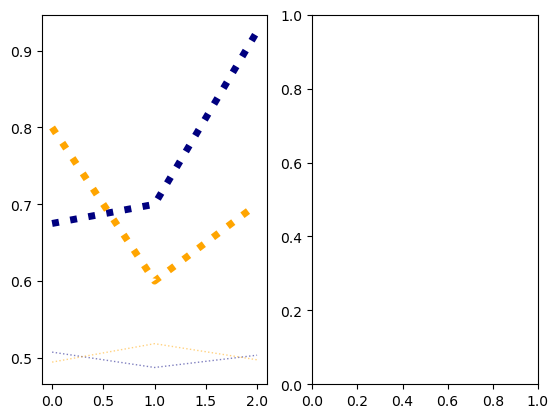

In [ ]:
# Big plot with all the accuracies per component and per models CLS and DIM RED
fig, ax = plt.subplots(1, 2)

method_dim_red = {'pca': ':', 'plssvd':'--'}
method_clf = {'LR' : ':', 'RandomForest':'--'}
modality = {'ieeg':'navy', 'meg':'orange'}

for m, a in zip(method_dim_red.keys(), ax):
    for model_name in method_clf.keys():
        for dataset_ in modality.keys():
            acc =[]
            acc_s =[]
            for PC_use in range(3) : 

                df_final = pd.read_csv(f'out/decoding/{dataset_}/{band}/fullmodel/{method_pca}_{data_aug_method}_{PC_use}_{model_name}full.csv')
                result = cleandfdecodingTS(df_final, len(time))
                acc.append(result['acc'])
                acc_s.append(result['acc_sh'])
            a.plot(acc, ls=method_clf[model_name], color=modality[dataset_],  alpha = 1, lw=3)
            a.plot(acc_s,  ls=method_clf[model_name], color=modality[dataset_], alpha = 0.5, lw=1)

            a.grid()